# Лабораторная 5. Временные ряды. Модели ARMA, ARIMA, SARIMA.
**Выполнила:** Окулова Александра ИТ-14


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
import time

warnings.simplefilter("ignore")

from itertools import product
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.eval_measures import mse
from statsmodels.tsa.statespace.tools import diff

def differencing(timeseries, s, D_max=2, d_max=2):
    seas_differenced = []
    timeseries = timeseries.copy()

    for i in range(D_max + 1):
        timeseries.name = f"d0_D{i}_s{s}"
        seas_differenced.append(timeseries)
        timeseries = timeseries.diff(periods=s)

    seas_df = pd.DataFrame(seas_differenced).T

    general_differenced = []

    for j, ts in enumerate(seas_differenced):
        for i in range(1, d_max + 1):
            ts = ts.diff()
            ts.name = f"d{i}_D{j}_s{s}"
            general_differenced.append(ts)

    gen_df = pd.DataFrame(general_differenced).T
    return pd.concat([seas_df, gen_df], axis=1)

def adf_summary(diff_series):
    summary = []

    for i in diff_series:
        a, b, c, d, e, f = adfuller(
            diff_series[i].dropna(),
            result_object=False
        )

        g, h, i = e.values()

        results = [a, b, c, d, g, h, i]
        summary.append(results)

    columns = [
        "Test Statistic",
        "p-value",
        "#Lags Used",
        "No. of Obs. Used",
        "Critical Value (1%)",
        "Critical Value (5%)",
        "Critical Value (10%)"
    ]

    index = diff_series.columns

    summary = pd.DataFrame(
        summary, index=index, columns=columns
    )

    return summary

def SARIMA_grid(endog, order, seasonal_order):
    model_info = []
    for i in tqdm(order):
        for j in seasonal_order:

            if i[1] == 0 and j[1] == 0:
                continue

            try:
                model_fit = SARIMAX(
                    endog=endog,
                    order=i,
                    seasonal_order=j
                ).fit(disp=False)

                predict = model_fit.predict()

                MAPE = (abs((endog-predict)[1:])/(endog[1:])).mean()
                MSE = mse(endog[1:], predict[1:])
                AIC = model_fit.aic
                BIC = model_fit.bic

                model_info.append([i, j, MAPE, MSE, AIC, BIC])

            except:
                continue

    columns = ["order", "seasonal_order", "MAPE", "MSE", "AIC", "BIC"]
    model_info = pd.DataFrame(data=model_info, columns=columns)
    return model_info


### Упражнение

Посмотрите на данные датчика, который отслеживает атмосферный CO2 из непрерывных проб воздуха в обсерватории Мауна-Лоа на Гавайях. Эти данные включают пробы CO2 с марта 1958 года по декабрь 1980 года.


In [2]:
co2 = pd.read_csv('https://zenodo.org/records/10951538/files/arima_co2.csv?download=1',
                  header = 0,
                  names = ['idx', 'co2'],
                  skipfooter = 2)

# convert the column idx into a datetime object and set it as the index
co2['idx'] = pd.to_datetime(co2['idx'])
co2.set_index('idx', inplace=True)

# Rmove the name "idx" from the index column
co2.index.name = None
co2

/tmp/ipykernel_5981/3622785519.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  co2 = pd.read_csv('https://zenodo.org/records/10951538/files/arima_co2.csv?download=1',


,co2
1965-01-01,319.32
1965-02-01,320.36
1965-03-01,320.82
1965-04-01,322.06
1965-05-01,322.17
...,...
1980-08-01,337.19
1980-09-01,335.49
1980-10-01,336.63
1980-11-01,337.74


- Определите наличие основного тренда и сезонности в данных.

- Определите, являются ли данные стационарными.

- Разделите данные на обучающие (90%) и тестовые (10%).

- Найдите набор моделей-кандидатов SARIMAX, посмотрев на ACF и PACF.

- Выполните поиск по сетке для моделей-кандидатов.

- Выберите лучшие модели на основе показателей производительности, сложности модели и нормальности остатков.

- Сравните лучшую найденную вами модель с моделью из autoarima.

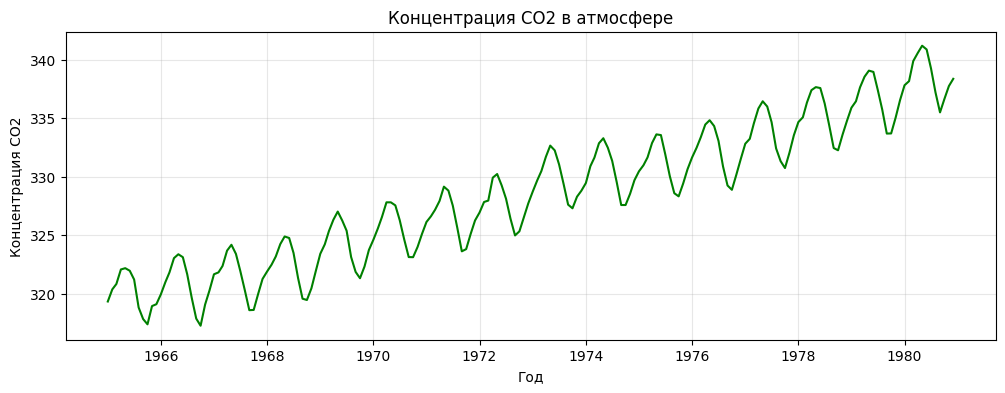

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(co2.index, co2['co2'], color='green')
plt.title("Концентрация CO2 в атмосфере")
plt.xlabel("Год")
plt.ylabel("Концентрация CO2")
plt.grid(alpha=0.3)

plt.show()

In [4]:
#Проверим стационарность
chunks = np.array_split(co2['co2'].values, 10)

print("Сводная статистика по фрагментам")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)

for i, chunk in enumerate(chunks, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(
        i, np.mean(chunk), np.var(chunk)
    ))

Сводная статистика по фрагментам
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | 320.67	 | 2.9374
 2	 | 321.19	 | 4.2736
 3	 | 323.28	 | 5.0044
 4	 | 326.08	 | 3.3136
 5	 | 326.93	 | 3.4605
 6	 | 330.55	 | 3.1118
 7	 | 330.67	 | 3.8107
 8	 | 332.91	 | 5.0103
 9	 | 335.55	 | 4.3787
10	 | 337.59	 | 4.7668


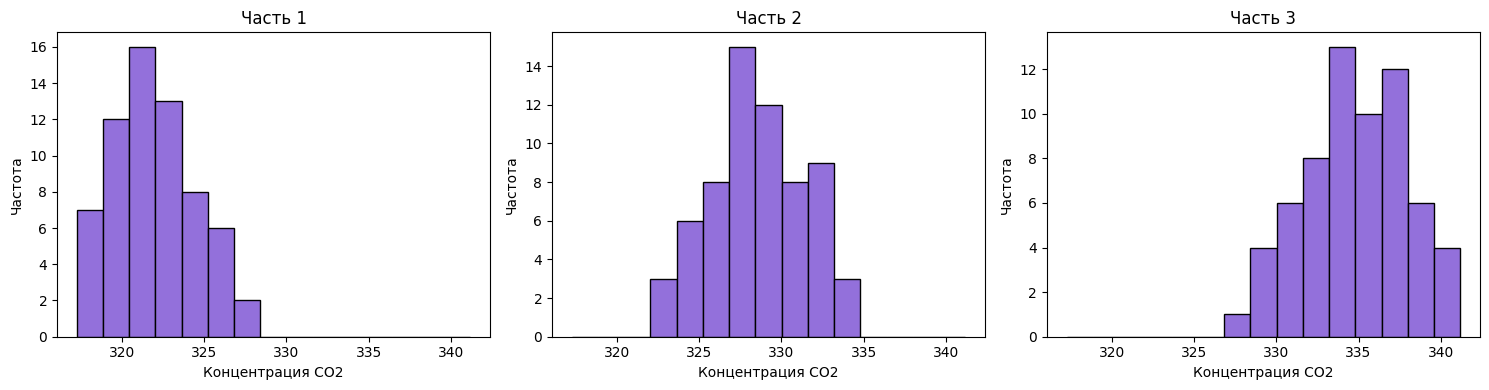

In [5]:
#Гистограммы
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
parts = np.array_split(co2['co2'].values, 3)
bins = np.histogram_bin_edges(co2['co2'], bins=15)

for i in range(3):
    axes[i].hist(parts[i], bins=bins,
                 color="mediumpurple", edgecolor="black")
    axes[i].set_title(f"Часть {i + 1}")
    axes[i].set_xlabel("Концентрация CO2")
    axes[i].set_ylabel("Частота")

plt.tight_layout()
plt.show()

In [6]:
adf_value, pvalue, _, _, critical_values, _ = adfuller(
    co2['co2'], result_object=False
)

print("тест Дики-Фуллера")
print(f"ADF: {adf_value:.3f}")
print(f"p-value: {pvalue:.6e}")
print("Критические значения:", critical_values)

тест Дики-Фуллера
ADF: 1.270
p-value: 9.964336e-01
Критические значения: {'1%': np.float64(-3.4674201432469816), '5%': np.float64(-2.877826051844538), '10%': np.float64(-2.575452082332012)}


Временной ряд имеет восходящий тренд и сезонность с периодом 12 месяцев. Амплитуда сезонных колебаний приблизительно постоянная.

Сводная статистика показывает увеличение среднего значения с 320.67 до 337.59. Гистограммы отдельных фрагментов постепенно смещаются вправо, следовательно среднее значение изменяется со временем.

По результатам теста Дики-Фуллера ADF = 1.270, p-value = 0.9964336. Поскольку p-value > 0.05, нулевая гипотеза о наличии единичного корня не отвергается.

Таким образом, исходный временной ряд является нестационарным.

In [7]:
#Разделение на обучающие и тестовые данные
train_size = int(len(co2) * 0.9)

train = co2['co2'].iloc[:train_size]
test = co2['co2'].iloc[train_size:]

print("Всего наблюдений:", len(co2))
print("Обучающая выборка:", len(train))
print("Тестовая выборка:", len(test))

Всего наблюдений: 192
Обучающая выборка: 172
Тестовая выборка: 20


In [8]:
diff_series = differencing(train, s=12, D_max=2, d_max=2)
diff_series

,d0_D0_s12,d0_D1_s12,d0_D2_s12,d1_D0_s12,d2_D0_s12,d1_D1_s12,d2_D1_s12,d1_D2_s12,d2_D2_s12
1965-01-01,319.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1965-02-01,320.36,NaN,NaN,1.04,NaN,NaN,NaN,NaN,NaN
1965-03-01,320.82,NaN,NaN,0.46,-0.58,NaN,NaN,NaN,NaN
1965-04-01,322.06,NaN,NaN,1.24,0.78,NaN,NaN,NaN,NaN
1965-05-01,322.17,NaN,NaN,0.11,-1.13,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
1978-12-01,334.76,1.23,-0.80,1.17,-0.17,-3.100000e-01,-0.33,-0.47,-0.48
1979-01-01,335.89,1.23,-0.62,1.13,-0.04,-5.684342e-14,0.31,0.18,0.65
1979-02-01,336.44,1.37,-0.47,0.55,-0.58,1.400000e-01,0.14,0.15,-0.03
1979-03-01,337.63,1.30,-0.48,1.19,0.64,-7.000000e-02,-0.21,-0.01,-0.16


In [9]:
summary = adf_summary(diff_series)
summary

,Test Statistic,p-value,#Lags Used,No. of Obs. Used,Critical Value (1%),Critical Value (5%),Critical Value (10%)
d0_D0_s12,0.495651,9.847403e-01,13,158,-3.472431,-2.880013,-2.576619
d0_D1_s12,-2.943016,4.056963e-02,14,145,-3.476273,-2.881688,-2.577513
d0_D2_s12,-3.431783,9.921946e-03,14,133,-3.480500,-2.883528,-2.578496
d1_D0_s12,-3.730704,3.701422e-03,12,158,-3.472431,-2.880013,-2.576619
d2_D0_s12,-10.425057,1.666045e-18,12,157,-3.472703,-2.880132,-2.576683
d1_D1_s12,-5.046955,1.790351e-05,12,146,-3.475953,-2.881548,-2.577439
d2_D1_s12,-5.081411,1.527708e-05,12,145,-3.476273,-2.881688,-2.577513
d1_D2_s12,-4.831338,4.735564e-05,14,132,-3.480888,-2.883697,-2.578586
d2_D2_s12,-4.792286,5.626425e-05,12,133,-3.480500,-2.883528,-2.578496


In [10]:
summary_passed = summary[summary["p-value"] < 0.05]
summary_passed

,Test Statistic,p-value,#Lags Used,No. of Obs. Used,Critical Value (1%),Critical Value (5%),Critical Value (10%)
d0_D1_s12,-2.943016,4.056963e-02,14,145,-3.476273,-2.881688,-2.577513
d0_D2_s12,-3.431783,9.921946e-03,14,133,-3.480500,-2.883528,-2.578496
d1_D0_s12,-3.730704,3.701422e-03,12,158,-3.472431,-2.880013,-2.576619
d2_D0_s12,-10.425057,1.666045e-18,12,157,-3.472703,-2.880132,-2.576683
d1_D1_s12,-5.046955,1.790351e-05,12,146,-3.475953,-2.881548,-2.577439
d2_D1_s12,-5.081411,1.527708e-05,12,145,-3.476273,-2.881688,-2.577513
d1_D2_s12,-4.831338,4.735564e-05,14,132,-3.480888,-2.883697,-2.578586
d2_D2_s12,-4.792286,5.626425e-05,12,133,-3.480500,-2.883528,-2.578496


In [11]:
index_list = pd.Index.tolist(summary_passed.index)
passed_series = diff_series[index_list].sort_index(axis=1)
passed_series

,d0_D1_s12,d0_D2_s12,d1_D0_s12,d1_D1_s12,d1_D2_s12,d2_D0_s12,d2_D1_s12,d2_D2_s12
1965-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1965-02-01,NaN,NaN,1.04,NaN,NaN,NaN,NaN,NaN
1965-03-01,NaN,NaN,0.46,NaN,NaN,-0.58,NaN,NaN
1965-04-01,NaN,NaN,1.24,NaN,NaN,0.78,NaN,NaN
1965-05-01,NaN,NaN,0.11,NaN,NaN,-1.13,NaN,NaN
...,...,...,...,...,...,...,...,...
1978-12-01,1.23,-0.80,1.17,-3.100000e-01,-0.47,-0.17,-0.33,-0.48
1979-01-01,1.23,-0.62,1.13,-5.684342e-14,0.18,-0.04,0.31,0.65
1979-02-01,1.37,-0.47,0.55,1.400000e-01,0.15,-0.58,0.14,-0.03
1979-03-01,1.30,-0.48,1.19,-7.000000e-02,-0.01,0.64,-0.21,-0.16


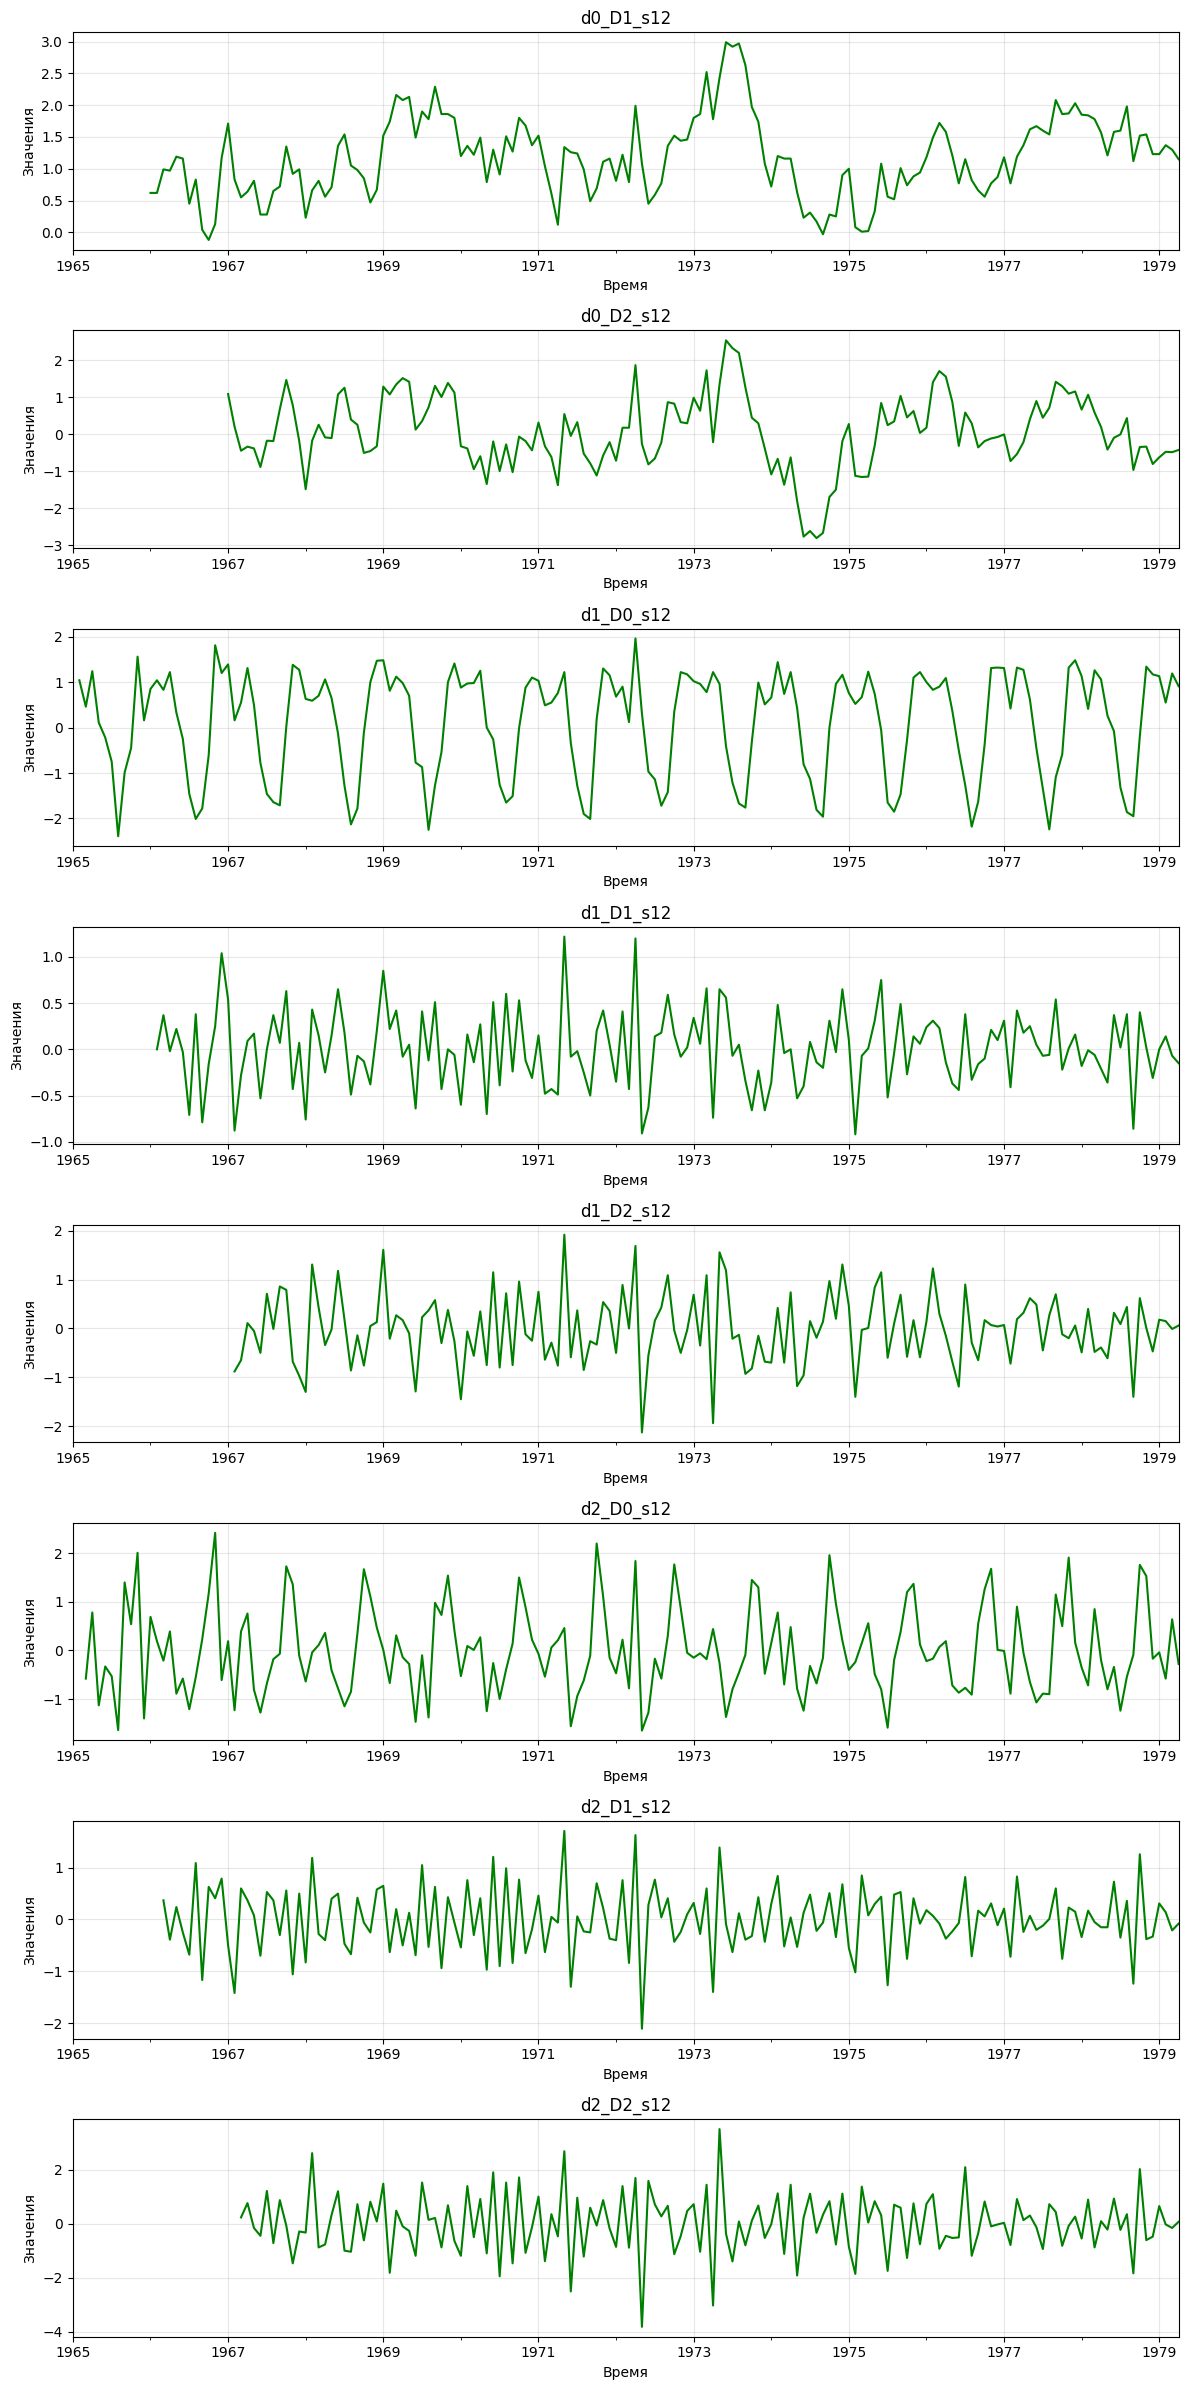

In [12]:
#Графики рядов после дифференцирования
fig, axes = plt.subplots(
    len(passed_series.columns), 1,
    figsize=(12, 3 * len(passed_series.columns)),
    squeeze=False
)

for i, column in enumerate(passed_series.columns):
    ax = axes[i, 0]
    passed_series[column].plot(
        ax=ax, color="green"
    )

    ax.set_title(column)
    ax.set_xlabel("Время")
    ax.set_ylabel("Значения")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

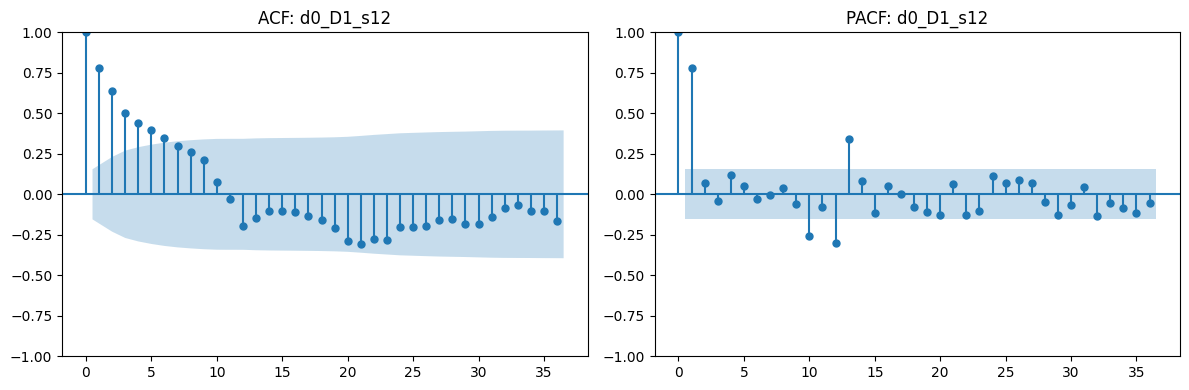

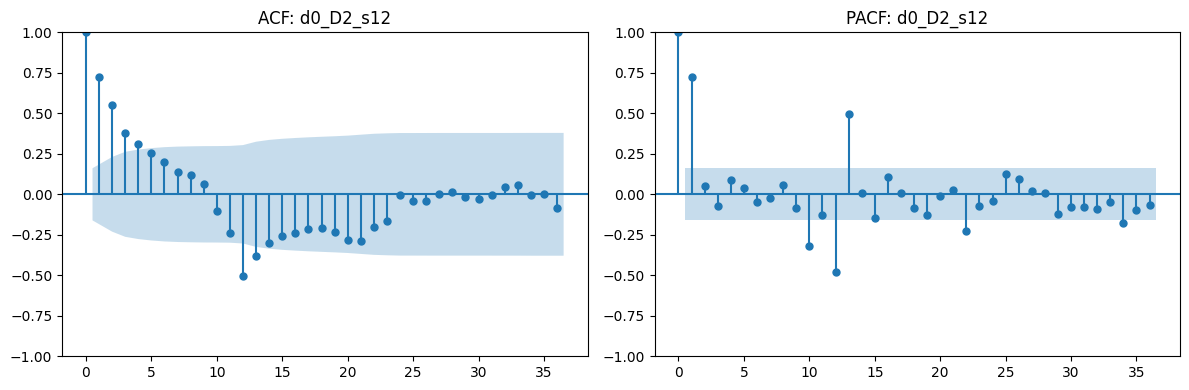

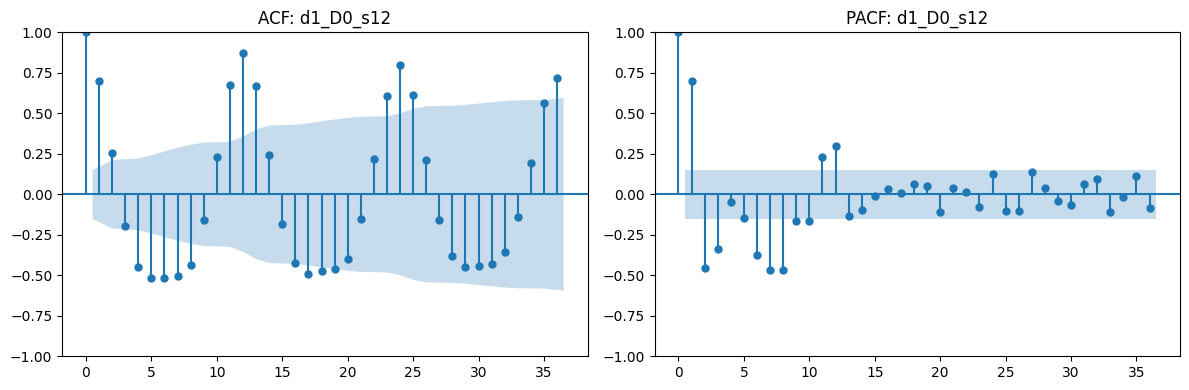

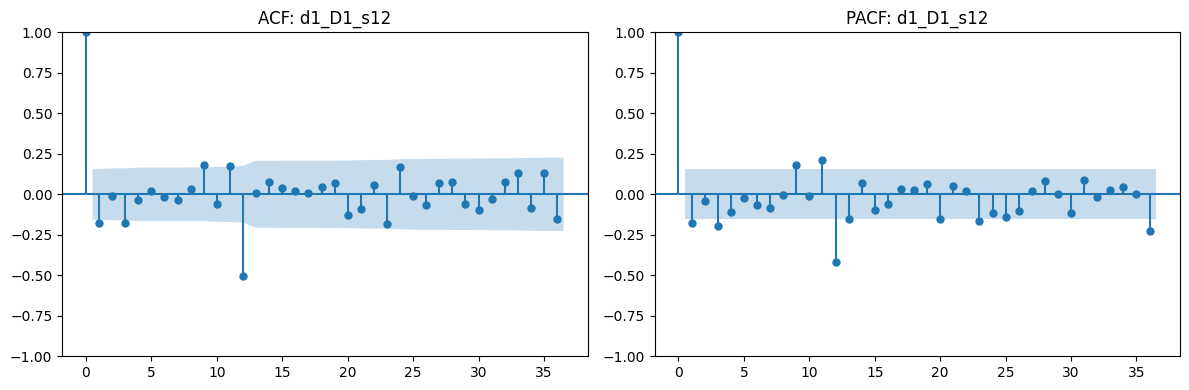

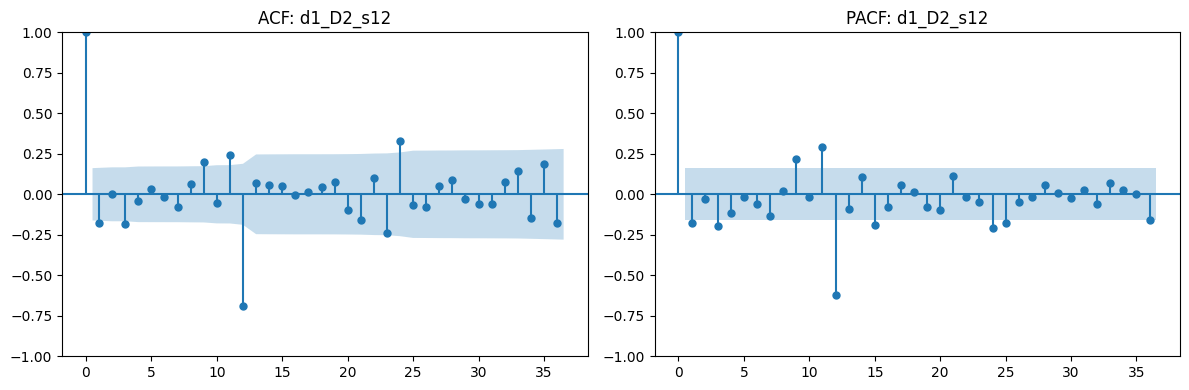

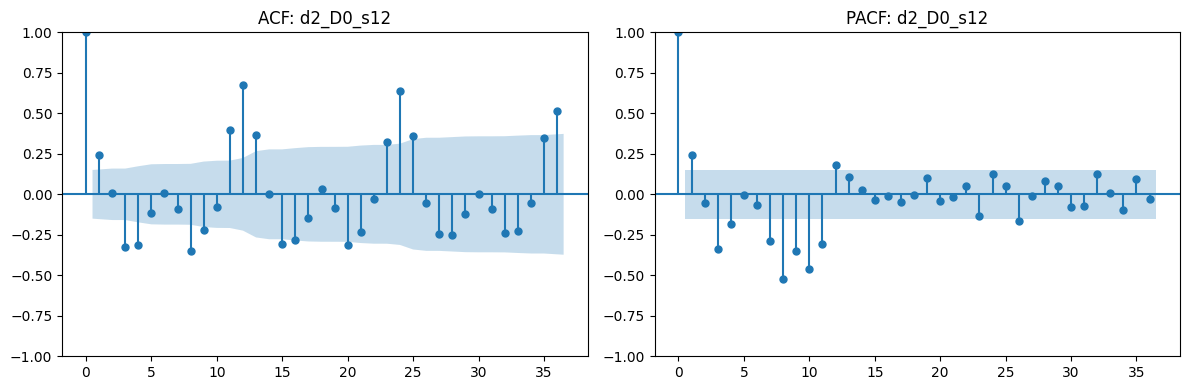

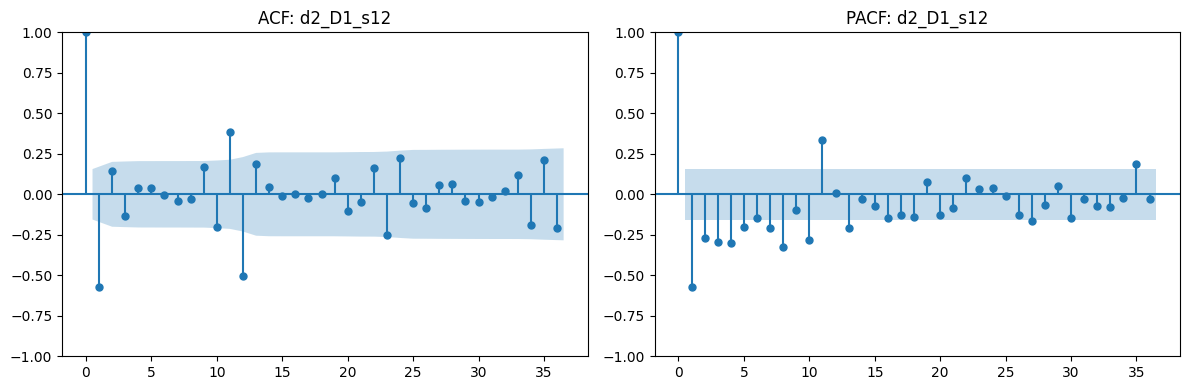

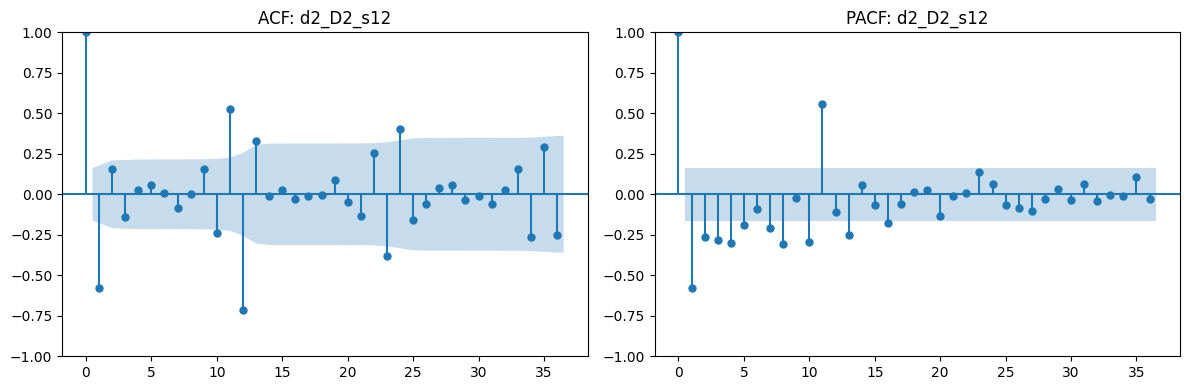

In [13]:
#ACF и PACF стационарных рядов
for column in passed_series.columns:
    data = passed_series[column].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    plot_acf(data, lags=36, ax=axes[0],
             title=f"ACF: {column}")

    plot_pacf(data, lags=36, ax=axes[1],
              title=f"PACF: {column}",
              method="ywm")

    plt.tight_layout()
    plt.show()

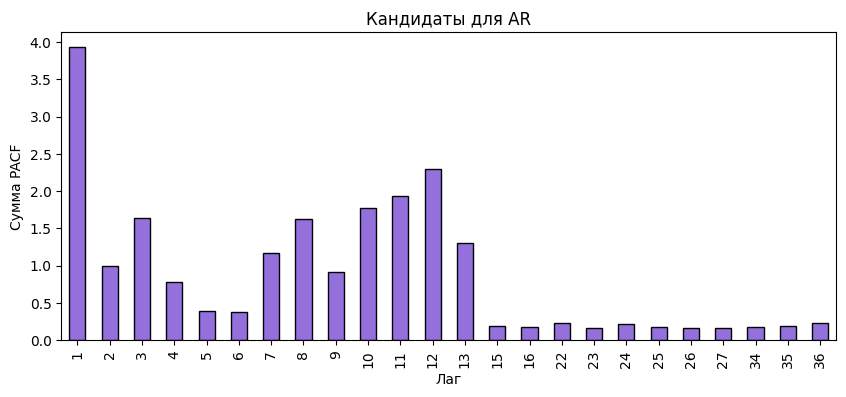

In [14]:
#Поиск значимых пиков PACF
df_sp_p = pd.DataFrame()

for i in passed_series:

    PACF, PACF_ci = pacf(
        passed_series[i].dropna(),
        nlags=36,
        alpha=0.05,
        method="ywm"
    )

    PACF_ci_ll = PACF_ci[:, 0] - PACF
    PACF_ci_ul = PACF_ci[:, 1] - PACF

    sp1 = np.where(PACF < PACF_ci_ll)[0]
    sp2 = np.where(PACF > PACF_ci_ul)[0]

    sp1_value = abs(PACF[PACF < PACF_ci_ll])
    sp2_value = PACF[PACF > PACF_ci_ul]

    sp1_series = pd.Series(sp1_value, index=sp1)
    sp2_series = pd.Series(sp2_value, index=sp2)

    df_sp_p = pd.concat(
        (df_sp_p, sp1_series, sp2_series), axis=1
    )

df_sp_p = df_sp_p.sort_index()

df_sp_p.drop(index=0, errors="ignore").T.sum().plot(
    kind="bar",
    title="Кандидаты для AR",
    xlabel="Лаг",
    ylabel="Сумма PACF",
    color="mediumpurple",
    edgecolor="black",
    figsize=(10, 4)
)

plt.show()

/tmp/ipykernel_5981/3198101302.py:6: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ACF, ACF_ci = acf(


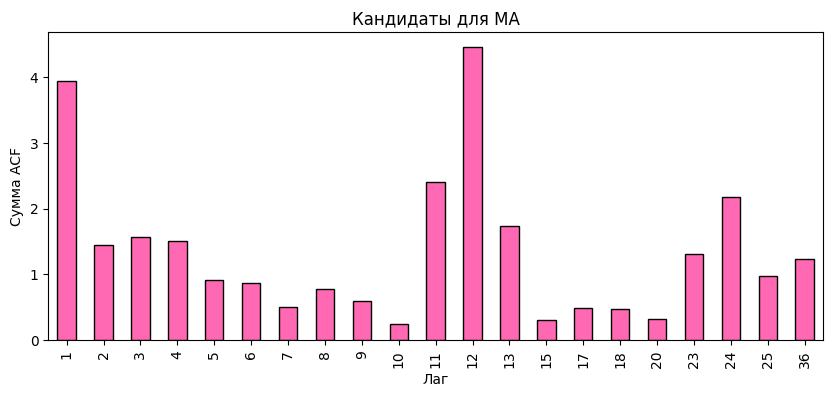

In [15]:
#Поиск значимых пиков ACF
df_sp_q = pd.DataFrame()

for i in passed_series:

    ACF, ACF_ci = acf(
        passed_series[i].dropna(),
        nlags=36,
        alpha=0.05
    )

    ACF_ci_ll = ACF_ci[:, 0] - ACF
    ACF_ci_ul = ACF_ci[:, 1] - ACF

    sp1 = np.where(ACF < ACF_ci_ll)[0]
    sp2 = np.where(ACF > ACF_ci_ul)[0]

    sp1_value = abs(ACF[ACF < ACF_ci_ll])
    sp2_value = ACF[ACF > ACF_ci_ul]

    sp1_series = pd.Series(sp1_value, index=sp1)
    sp2_series = pd.Series(sp2_value, index=sp2)

    df_sp_q = pd.concat(
        (df_sp_q, sp1_series, sp2_series), axis=1
    )

df_sp_q = df_sp_q.sort_index()

df_sp_q.drop(index=0, errors="ignore").T.sum().plot(
    kind="bar",
    title="Кандидаты для MA",
    xlabel="Лаг",
    ylabel="Сумма ACF",
    color="hotpink",
    edgecolor="black",
    figsize=(10, 4)
)

plt.show()

### Определение моделей-кандидатов

Для определения параметров дифференцирования рассмотрены девять сочетаний d и D. По результатам теста Дики-Фуллера восемь преобразованных рядов имеют p-value < 0.05.

Для дальнейшего анализа выбраны сочетания (d, D): (0, 1), (1, 0), (1, 1).

На основе анализа значимых пиков графиков PACF и ACF определены следующие параметры моделей-кандидатов:

- p = [0, 1, 3];
- q = [0, 1, 3];
- P = [0, 1];
- Q = [0, 1, 2];
- s = 12.


In [18]:
#Возможные значения параметров
p = [0, 1, 3]
d = [0, 1]
q = [0, 1, 3]
P = [0, 1]
D = [0, 1]
Q = [0, 1, 2]
s = [12]

#Создание всех комбинаций параметров
pdq = list(product(p, d, q))
PDQm = list(product(P, D, Q, s))

print(f"Количество комбинаций: {len(pdq)*len(PDQm)}")

Количество комбинаций: 216


In [22]:
train = train.asfreq("MS")
test = test.asfreq("MS")

#Поиск по сетке
start = time.time()

model_info = SARIMA_grid(
    endog=train,
    order=pdq,
    seasonal_order=PDQm
)

end = time.time()

print(f"Время выполнения: {end - start:.2f} сек.")

model_info


100%|██████████| 18/18 [05:35<00:00, 18.62s/it]

Время выполнения: 335.16 сек.


,order,seasonal_order,MAPE,MSE,AIC,BIC
0,"(0, 0, 0)","(0, 1, 0, 12)",0.067671,6591.126519,546.385150,549.460324
1,"(0, 0, 0)","(0, 1, 1, 12)",0.066895,6590.609102,489.617928,495.768276
2,"(0, 0, 0)","(0, 1, 2, 12)",0.066625,6590.412418,461.948964,471.174485
3,"(0, 0, 0)","(1, 1, 0, 12)",0.066327,6590.265197,433.755633,439.905981
4,"(0, 0, 0)","(1, 1, 1, 12)",0.065967,6589.985912,365.504280,374.729801
...,...,...,...,...,...,...
157,"(3, 1, 3)","(1, 0, 1, 12)",0.000958,0.187717,153.413819,181.688791
158,"(3, 1, 3)","(1, 0, 2, 12)",0.000933,0.180971,149.866764,181.283400
159,"(3, 1, 3)","(1, 1, 0, 12)",0.003846,147.669687,118.065571,142.616805
160,"(3, 1, 3)","(1, 1, 1, 12)",0.003795,147.658235,95.550669,123.170807


In [36]:
print("10 лучших моделей по MAPE")
least_MAPE = model_info.nsmallest(10, "MAPE")
least_MAPE

10 лучших моделей по MAPE


,order,seasonal_order,MAPE,MSE,AIC,BIC
103,"(1, 1, 3)","(1, 0, 1, 12)",0.000931,0.175207,134.081185,156.072830
158,"(3, 1, 3)","(1, 0, 2, 12)",0.000933,0.180971,149.866764,181.283400
104,"(1, 1, 3)","(1, 0, 2, 12)",0.000937,0.174395,138.414892,163.548201
145,"(3, 1, 1)","(1, 0, 1, 12)",0.000942,0.175338,138.476168,160.467813
146,"(3, 1, 1)","(1, 0, 2, 12)",0.000947,0.177908,143.003746,168.137054
26,"(0, 1, 0)","(1, 0, 2, 12)",0.000947,0.185938,142.423229,154.989883
92,"(1, 1, 1)","(1, 0, 2, 12)",0.000947,0.183360,135.874747,154.724728
91,"(1, 1, 1)","(1, 0, 1, 12)",0.000947,0.184463,133.573494,149.281812
25,"(0, 1, 0)","(1, 0, 1, 12)",0.000948,0.186017,140.139042,149.564033
49,"(0, 1, 3)","(1, 0, 1, 12)",0.000951,0.191884,133.891795,152.741776


In [35]:
print("10 лучших моделей по MSE")
least_MSE = model_info.nsmallest(10, "MSE")
least_MSE

10 лучших моделей по MSE


,order,seasonal_order,MAPE,MSE,AIC,BIC
104,"(1, 1, 3)","(1, 0, 2, 12)",0.000937,0.174395,138.414892,163.548201
103,"(1, 1, 3)","(1, 0, 1, 12)",0.000931,0.175207,134.081185,156.072830
145,"(3, 1, 1)","(1, 0, 1, 12)",0.000942,0.175338,138.476168,160.467813
146,"(3, 1, 1)","(1, 0, 2, 12)",0.000947,0.177908,143.003746,168.137054
158,"(3, 1, 3)","(1, 0, 2, 12)",0.000933,0.180971,149.866764,181.283400
92,"(1, 1, 1)","(1, 0, 2, 12)",0.000947,0.183360,135.874747,154.724728
91,"(1, 1, 1)","(1, 0, 1, 12)",0.000947,0.184463,133.573494,149.281812
26,"(0, 1, 0)","(1, 0, 2, 12)",0.000947,0.185938,142.423229,154.989883
25,"(0, 1, 0)","(1, 0, 1, 12)",0.000948,0.186017,140.139042,149.564033
157,"(3, 1, 3)","(1, 0, 1, 12)",0.000958,0.187717,153.413819,181.688791


In [34]:
print("10 лучших моделей по AIC")
least_AIC = model_info.nsmallest(10, "AIC")
least_AIC

10 лучших моделей по AIC


,order,seasonal_order,MAPE,MSE,AIC,BIC
34,"(0, 1, 1)","(0, 1, 1, 12)",0.003812,147.662389,90.470643,99.677356
46,"(0, 1, 3)","(0, 1, 1, 12)",0.003802,147.659073,90.699192,106.043713
88,"(1, 1, 1)","(0, 1, 1, 12)",0.003808,147.660730,91.093682,103.369299
76,"(1, 1, 0)","(0, 1, 1, 12)",0.003810,147.663009,91.389495,100.596207
40,"(0, 1, 1)","(1, 1, 1, 12)",0.003811,147.662522,92.321363,104.596980
100,"(1, 1, 3)","(0, 1, 1, 12)",0.003803,147.658893,92.326828,110.740254
35,"(0, 1, 1)","(0, 1, 2, 12)",0.003811,147.662505,92.337678,104.613294
142,"(3, 1, 1)","(0, 1, 1, 12)",0.003802,147.658778,92.366317,110.779742
52,"(0, 1, 3)","(1, 1, 1, 12)",0.003802,147.659118,92.691050,111.104475
47,"(0, 1, 3)","(0, 1, 2, 12)",0.003802,147.659113,92.694369,111.107794


In [33]:
print("10 лучших моделей по BIC")
least_BIC = model_info.nsmallest(10, "BIC")
least_BIC

10 лучших моделей по BIC


,order,seasonal_order,MAPE,MSE,AIC,BIC
34,"(0, 1, 1)","(0, 1, 1, 12)",0.003812,147.662389,90.470643,99.677356
76,"(1, 1, 0)","(0, 1, 1, 12)",0.003810,147.663009,91.389495,100.596207
88,"(1, 1, 1)","(0, 1, 1, 12)",0.003808,147.660730,91.093682,103.369299
40,"(0, 1, 1)","(1, 1, 1, 12)",0.003811,147.662522,92.321363,104.596980
35,"(0, 1, 1)","(0, 1, 2, 12)",0.003811,147.662505,92.337678,104.613294
82,"(1, 1, 0)","(1, 1, 1, 12)",0.003809,147.663153,93.194939,105.470555
77,"(1, 1, 0)","(0, 1, 2, 12)",0.003809,147.663136,93.221845,105.497462
46,"(0, 1, 3)","(0, 1, 1, 12)",0.003802,147.659073,90.699192,106.043713
22,"(0, 1, 0)","(0, 1, 1, 12)",0.003830,147.669898,101.557375,107.695184
61,"(1, 0, 1)","(0, 1, 1, 12)",0.065080,6589.471742,95.862103,108.162798


In [29]:
set(least_MAPE.index) & set(least_MSE.index)

{25, 26, 91, 92, 103, 104, 145, 146, 158}

In [30]:
set(least_AIC.index) & set(least_BIC.index)

{34, 35, 40, 46, 76, 88}

In [31]:
set(least_MSE.index) & set(least_AIC.index)

set()

In [37]:
print("Лучшая модель по каждому критерию")
L1 = model_info[model_info.MAPE == model_info.MAPE.min()]
L2 = model_info[model_info.MSE == model_info.MSE.min()]
L3 = model_info[model_info.AIC == model_info.AIC.min()]
L4 = model_info[model_info.BIC == model_info.BIC.min()]

best_models = pd.concat((L1, L2, L3, L4))
best_models

Лучшая модель по каждому критерию


,order,seasonal_order,MAPE,MSE,AIC,BIC
103,"(1, 1, 3)","(1, 0, 1, 12)",0.000931,0.175207,134.081185,156.072830
104,"(1, 1, 3)","(1, 0, 2, 12)",0.000937,0.174395,138.414892,163.548201
34,"(0, 1, 1)","(0, 1, 1, 12)",0.003812,147.662389,90.470643,99.677356
34,"(0, 1, 1)","(0, 1, 1, 12)",0.003812,147.662389,90.470643,99.677356


In [38]:
ord_list = [tuple(best_models.iloc[i, 0])
            for i in range(best_models.shape[0])]

s_ord_list = [tuple(best_models.iloc[i, 1])
              for i in range(best_models.shape[0])]

preds, ci_low, ci_up, MAPE_test = [], [], [], []
MSE_test = []
fitted_models = []

#Обучаем модели и строим прогнозы
for i in range(4):

    model_fit = SARIMAX(
        endog=train,
        order=ord_list[i],
        seasonal_order=s_ord_list[i]
    ).fit(disp=False)

    pred_summary = model_fit.get_prediction(
        test.index[0],
        test.index[-1]
    ).summary_frame()

    preds.append(pred_summary['mean'])

    ci_low.append(pred_summary['mean_ci_lower'][test.index])
    ci_up.append(pred_summary['mean_ci_upper'][test.index])

    MAPE_test.append(
        (abs((test - pred_summary['mean']) / test)).mean()
    )

    MSE_test.append(mse(test, pred_summary['mean']))
    fitted_models.append(model_fit)

    print("Модель:", ord_list[i], s_ord_list[i])
    print("Сходимость:", model_fit.mle_retvals['converged'])
    print(f"MAPE: {MAPE_test[i]:.2%}")
    print(f"MSE: {MSE_test[i]:.5f}")
    print()

Модель: (1, 1, 3) (1, 0, 1, 12)
Сходимость: False
MAPE: 0.19%
MSE: 0.68509

Модель: (1, 1, 3) (1, 0, 2, 12)
Сходимость: False
MAPE: 0.23%
MSE: 0.93222

Модель: (0, 1, 1) (0, 1, 1, 12)
Сходимость: True
MAPE: 0.19%
MSE: 0.66862

Модель: (0, 1, 1) (0, 1, 1, 12)
Сходимость: True
MAPE: 0.19%
MSE: 0.66862



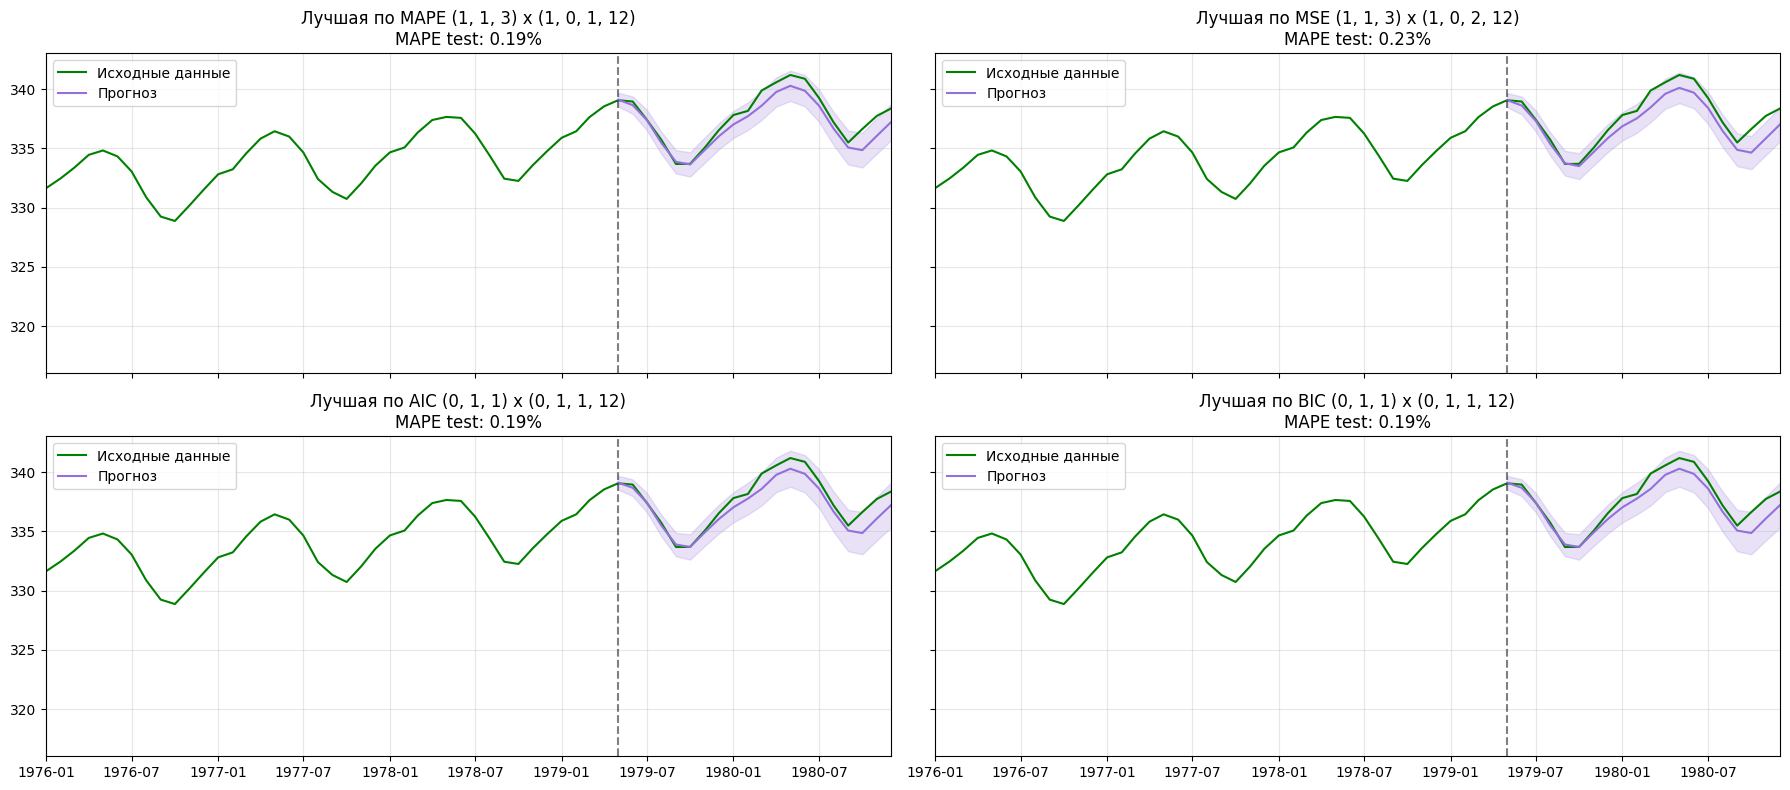

In [40]:
#Графики прогнозов лучших моделей
fig, axs = plt.subplots(
    nrows=2, ncols=2,
    figsize=(18, 8),
    sharex=True, sharey=True
)

titles = [
    f'Лучшая по MAPE {ord_list[0]} x {s_ord_list[0]}',
    f'Лучшая по MSE {ord_list[1]} x {s_ord_list[1]}',
    f'Лучшая по AIC {ord_list[2]} x {s_ord_list[2]}',
    f'Лучшая по BIC {ord_list[3]} x {s_ord_list[3]}'
]

k = 0

for i in range(2):

    for j in range(2):

        axs[i, j].plot(
            co2['co2'],
            color='green',
            label='Исходные данные'
        )

        axs[i, j].plot(
            preds[k],
            color='mediumpurple',
            label='Прогноз'
        )

        axs[i, j].set_title(
            titles[k] + f'\nMAPE test: {MAPE_test[k]:.2%}'
        )

        axs[i, j].legend()

        axs[i, j].axvline(
            test.index[0],
            color='black',
            alpha=0.5,
            linestyle='--'
        )

        axs[i, j].fill_between(
            x=test.index,
            y1=ci_low[k],
            y2=ci_up[k],
            color='mediumpurple',
            alpha=0.2
        )

        axs[i, j].set_xlim(
            left=co2.index[-60],
            right=co2.index[-1]
        )

        axs[i, j].grid(alpha=0.3)

        k += 1

plt.tight_layout()
plt.show()

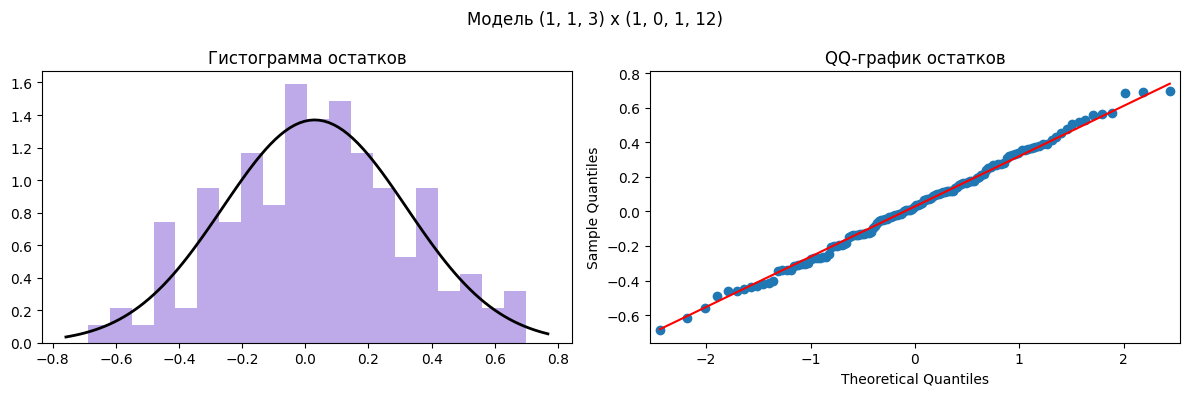

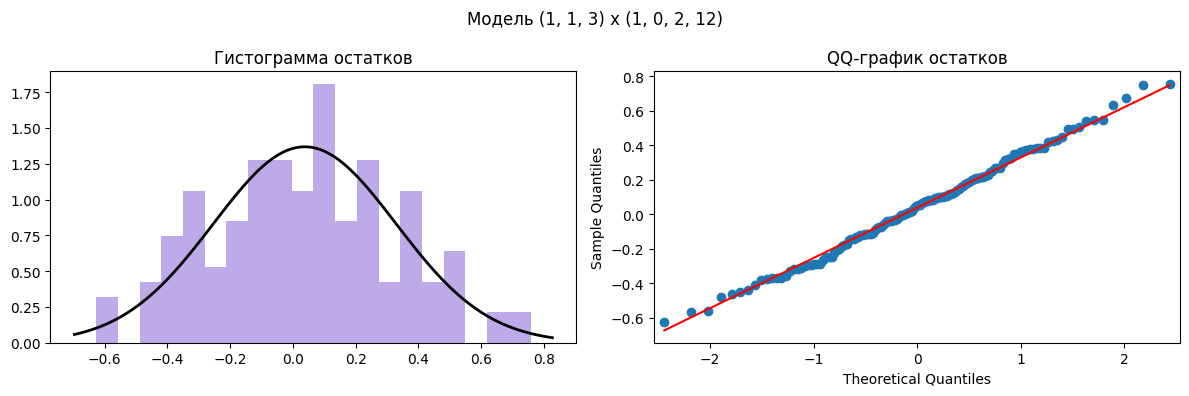

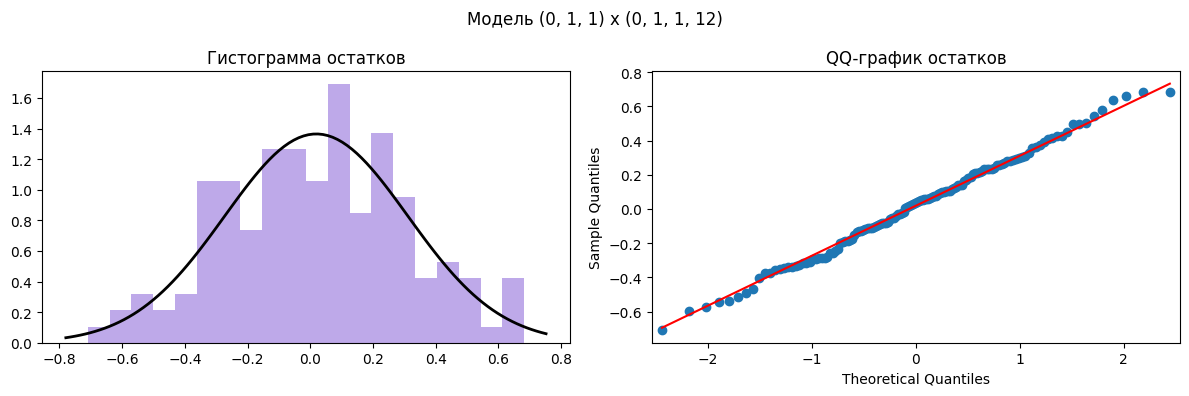

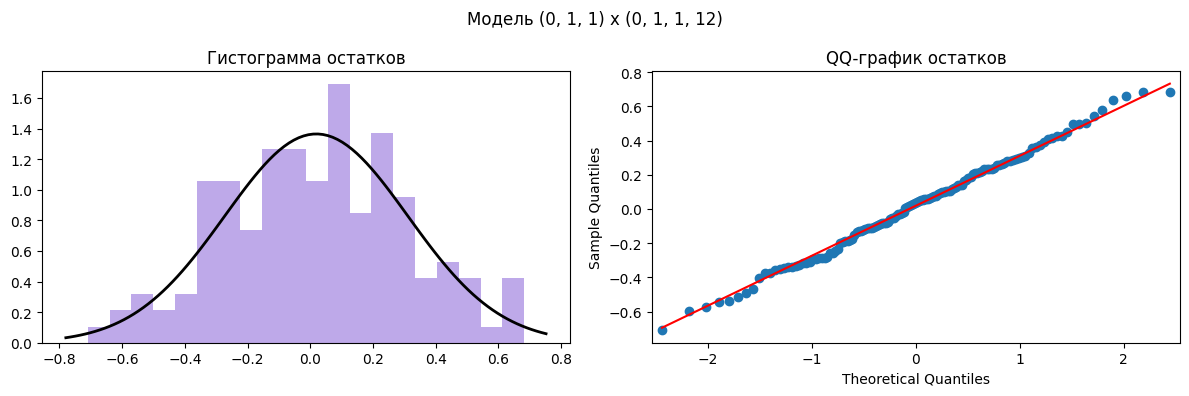

In [42]:
for i in range(4):
    residuals = fitted_models[i].resid.iloc[36:]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    #Гистограмма остатков
    axes[0].hist(
        residuals,
        bins=20,
        density=True,
        alpha=0.6,
        color='mediumpurple'
    )

    #Кривая нормального распределения
    xmin, xmax = axes[0].get_xlim()
    x = np.linspace(xmin, xmax, 100)

    p = stats.norm.pdf(
        x,
        np.mean(residuals),
        np.std(residuals)
    )

    axes[0].plot(x, p, 'k', linewidth=2)
    axes[0].set_title("Гистограмма остатков")

    #QQ-график
    qqplot(residuals, line='s', ax=axes[1])
    axes[1].set_title("QQ-график остатков")

    fig.suptitle(
        f"Модель {ord_list[i]} x {s_ord_list[i]}"
    )

    plt.tight_layout()
    plt.show()

In [43]:
#Тесты нормальности остатков
JB_pvalues = []
Shapiro_pvalues = []

for i in range(4):

    residuals = fitted_models[i].resid.iloc[36:]

    jb_test = stats.jarque_bera(residuals)
    shapiro_test = stats.shapiro(residuals)

    JB_pvalues.append(jb_test.pvalue)
    Shapiro_pvalues.append(shapiro_test.pvalue)

    print("Модель:", ord_list[i], s_ord_list[i])

    print(f"Жак-Бера p-value: {jb_test.pvalue:.6f}")
    print(f"Шапиро-Уилк p-value: {shapiro_test.pvalue:.6f}")
    print()

Модель: (1, 1, 3) (1, 0, 1, 12)
Жак-Бера p-value: 0.615991
Шапиро-Уилк p-value: 0.846332

Модель: (1, 1, 3) (1, 0, 2, 12)
Жак-Бера p-value: 0.527899
Шапиро-Уилк p-value: 0.746962

Модель: (0, 1, 1) (0, 1, 1, 12)
Жак-Бера p-value: 0.661152
Шапиро-Уилк p-value: 0.776757

Модель: (0, 1, 1) (0, 1, 1, 12)
Жак-Бера p-value: 0.661152
Шапиро-Уилк p-value: 0.776757



In [44]:
#Сравнение лучших моделей
results = pd.DataFrame({
    "order": ord_list,
    "seasonal_order": s_ord_list,
    "MAPE_test": MAPE_test,
    "MSE_test": MSE_test,
    "AIC": [model.aic for model in fitted_models],
    "BIC": [model.bic for model in fitted_models],
    "Jarque-Bera": JB_pvalues,
    "Shapiro-Wilk": Shapiro_pvalues,
    "Converged": [
        model.mle_retvals['converged']
        for model in fitted_models
    ]
})
results

,order,seasonal_order,MAPE_test,MSE_test,AIC,BIC,Jarque-Bera,Shapiro-Wilk,Converged
0,"(1, 1, 3)","(1, 0, 1, 12)",0.001929,0.685091,134.081185,156.072830,0.615991,0.846332,False
1,"(1, 1, 3)","(1, 0, 2, 12)",0.002323,0.932218,138.414892,163.548201,0.527899,0.746962,False
2,"(0, 1, 1)","(0, 1, 1, 12)",0.001883,0.668622,90.470643,99.677356,0.661152,0.776757,True
3,"(0, 1, 1)","(0, 1, 1, 12)",0.001883,0.668622,90.470643,99.677356,0.661152,0.776757,True


### Выбор лучшей модели

По результатам сравнения трёх уникальных моделей на тестовой выборке наилучшие показатели получены для модели SARIMA(0,1,1)(0,1,1,12).

Среднеквадратичная ошибка составила MSE = 0.668622, а средняя абсолютная процентная ошибка - MAPE = 0.1883%.

Данная модель также имеет наименьшие значения AIC = 90.470643 и BIC = 99.677356

По результатам проверки нормальности остатков:

- тест Жака - Бера: p-value = 0.661152;
- тест Шапиро - Уилка: p-value = 0.776757.

В обоих случаях p-value > 0.05, поэтому нет оснований отвергать гипотезу о нормальности остатков.

При обучении модели достигнута сходимость оптимизации, в отличие от двух других моделей-кандидатов.

Таким образом, для дальнейшего сравнения выбрана модель SARIMA(0,1,1)(0,1,1,12)

In [46]:
!pip install -U -qq pmdarima

In [54]:
import pmdarima as pm

#Автоматический подбор модели ARIMA
model = pm.auto_arima(
    train,
    start_p=0, start_q=0,
    test='adf',
    max_p=2, max_q=2,
    m=12,
    start_P=0, start_Q=0,
    max_P=2, max_Q=2,
    seasonal=True,
    d=None,
    D=1,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=170.140, Time=0.06 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=116.893, Time=0.34 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=1.82 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=167.257, Time=0.09 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=112.261, Time=0.43 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=2.56 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=1.46 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=116.848, Time=0.31 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=114.093, Time=0.68 sec
 ARIMA(1,1,1)(2,1,0)[12]             : AIC=111.836, Time=0.85 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=116.214, Time=0.30 sec
 ARIMA(1,1,1)(2,1,1)[12]             : AIC=inf, Time=2.56 sec
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=3.69 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=111.627, Time=0.42 sec
 ARIMA(0,1,1)(1,1,0)[12]             : AIC=116.499, T

In [50]:
print(model.summary())
print("Порядок модели:", model.order)
print("Сезонный порядок:", model.seasonal_order)

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  172
Model:             SARIMAX(0, 1, 1)x(2, 1, [], 12)   Log Likelihood                 -51.813
Date:                             Thu, 12 Nov 2026   AIC                            111.627
Time:                                     17:26:45   BIC                            123.903
Sample:                                 01-01-1965   HQIC                           116.612
                                      - 04-01-1979                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2328      0.069     -3.352      0.001      -0.369      -0.097
ar.S.L12      -0.6797      

In [51]:
#Прогноз AutoARIMA
forecast_auto = model.predict(n_periods=len(test))

forecast_auto = pd.Series(
    np.asarray(forecast_auto),
    index=test.index
)
#Расчет ошибок
MSE_auto = mse(test, forecast_auto)
MAPE_auto = (abs((test - forecast_auto) / test)).mean()

print(f"MSE AutoARIMA: {MSE_auto:.6f}")
print(f"MAPE AutoARIMA: {MAPE_auto:.4%}")

MSE AutoARIMA: 0.517895
MAPE AutoARIMA: 0.1675%


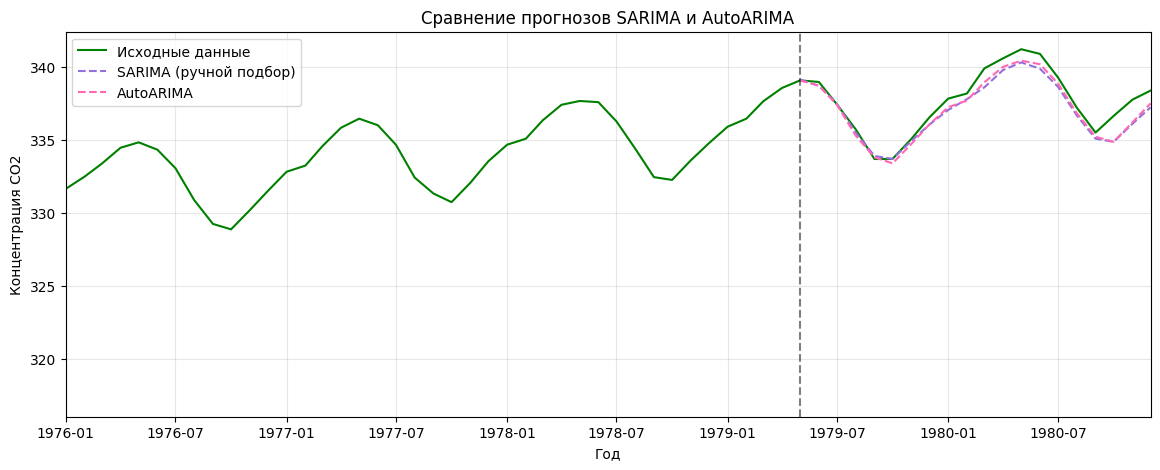

In [52]:
plt.figure(figsize=(14, 5))
plt.plot(
    co2.index, co2['co2'],
    color='green',
    label='Исходные данные'
)

plt.plot(
    test.index, preds[2],
    color='mediumpurple',
    linestyle='--',
    label='SARIMA (ручной подбор)'
)

plt.plot(
    test.index, forecast_auto,
    color='hotpink',
    linestyle='--',
    label='AutoARIMA'
)

plt.axvline(
    test.index[0],
    color='black',
    linestyle='--',
    alpha=0.5
)

plt.xlim(co2.index[-60], co2.index[-1])

plt.title("Сравнение прогнозов SARIMA и AutoARIMA")
plt.xlabel("Год")
plt.ylabel("Концентрация CO2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [53]:
#Сравнение лучшей модели и AutoARIMA
comparison = pd.DataFrame({
    "Метод": ["Grid Search", "AutoARIMA"],
    "order": [ord_list[2], model.order],
    "seasonal_order": [s_ord_list[2], model.seasonal_order],
    "MSE": [MSE_test[2], MSE_auto],
    "MAPE": [MAPE_test[2], MAPE_auto],
    "AIC": [fitted_models[2].aic, model.aic()],
    "BIC": [fitted_models[2].bic, model.bic()]
})
comparison

,Метод,order,seasonal_order,MSE,MAPE,AIC,BIC
0,Grid Search,"(0, 1, 1)","(0, 1, 1, 12)",0.668622,0.001883,90.470643,99.677356
1,AutoARIMA,"(0, 1, 1)","(2, 1, 0, 12)",0.517895,0.001675,111.626929,123.902546


## Вывод

В ходе лабораторной работы исследован временной ряд концентрации CO2 в атмосфере. Выявлены восходящий тренд и сезонность с периодом 12 месяцев. С помощью сводной статистики, гистограмм и теста Дики-Фуллера установлено, что исходный ряд является нестационарным.

Данные разделены на обучающую и тестовую выборки, содержащие 172 и 20 наблюдений соответственно.

На основе анализа графиков ACF и PACF определены параметры моделей-кандидатов SARIMAX. Выполнен поиск по сетке, в ходе которого рассмотрены 162 модели. Модели сравнивались по критериям MAPE, MSE, AIC и BIC.

По результатам сравнения точности прогнозирования, сложности моделей, сходимости оптимизации и нормальности остатков выбрана модель SARIMA(0,1,1)(0,1,1,12). На тестовой выборке получены MSE = 0.668622 и MAPE = 0.1883%.

С помощью AutoARIMA найдена модель SARIMA(0,1,1)(2,1,0,12). Для неё получены MSE = 0.517895 и MAPE = 0.1675%.

При сравнении моделей установлено, что AutoARIMA обеспечивает более точный прогноз на тестовой выборке. Однако модель, найденная с помощью Grid Search, имеет меньшие значения информационных критериев AIC и BIC и более простую структуру.

Таким образом, ручной и автоматический подбор параметров позволяют получить разные модели для одного временного ряда. Выбор модели зависит от цели исследования.